# TA-EVRP Thesis Figures

Figures for the PSL and SVC Traffic results subsections.
Outputs saved to `results/figures/`.

| Figure | File | Description |
|--------|------|--------------|
| 1 | `ta_evrp_psl_planner_agent_comparison.png` | 2x2 grid: columns = EVRP planner (MILP, Heuristic), rows = metric (makespan, total distance); each panel is a line plot over networks comparing Dijkstra vs DQN, averaged over PSL slot count $K=1$–$4$. Source: `results/ta_evrp_results_raps_psl_vmin5.csv` |
| 2 | `ta_evrp_psl_planner_allagents_comparison.png` | Same 2x2 layout as Figure 1, but grouped bar charts covering all TRSP agents (Dijkstra, SARSA, DQN, PPO, A2C; DSP excluded). Source: `results/ta_evrp_results_psl_thesis.csv` |
| 3 | `ta_evrp_psl_makespan_k_breakdown.png` | 2x5 grid: rows = EVRP planner (MILP, Heuristic), columns = $K=1$–$4$ plus the all-$K$ average; each panel is a grouped bar chart of mean makespan over networks, one bar group per agent. Source: `results/ta_evrp_results_psl_thesis.csv` |
| 4 | `ta_evrp_psl_distance_k_breakdown.png` | Same layout as Figure 3, for mean total distance. Source: `results/ta_evrp_results_psl_thesis.csv` |
| 5 | `ta_evrp_svc_planner_agent_comparison.png` | 2x2 grid: rows = EVRP planner (MILP, Heuristic), columns = metric (makespan, total distance); each panel is a grouped bar chart over networks, one bar group per TRSP agent (all six, including DSP). Source: `results/ta_evrp_results_svc_thesis.csv` |

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# serif fonts to match LaTeX output
plt.rcParams.update({
    'font.size': 11,
    'font.family': 'serif',
    'axes.labelsize': 11,
    'axes.titlesize': 12,
    'legend.fontsize': 9,
    'xtick.labelsize': 9,
    'ytick.labelsize': 9,
})

BASE = Path('..').resolve()
FIG_DIR = BASE / 'results' / 'figures'
FIG_DIR.mkdir(parents=True, exist_ok=True)
print('Base:', BASE)
print('Figures will be saved to:', FIG_DIR)

Base: /home/shinobi-owl/PhD/battery/DroneSim
Figures will be saved to: /home/shinobi-owl/PhD/battery/DroneSim/results/figures


## Constants

In [2]:
NET_PATH = {
    'Grid':      'data/grid_road/grid_road.sumocfg',
    'Rand-Grid': 'data/rand_grid_road/rand_grid_road_final.sumocfg',
    'Ames':      'data/ames/ames_campus_final.sumocfg',
}
NET_ORDER = ['Grid', 'Rand-Grid', 'Ames']
NET_CODE = {v: k for k, v in NET_PATH.items()}

PLANNER_ORDER  = ['milp', 'heuristic']
PLANNER_LABELS = {'milp': 'MILP', 'heuristic': 'Heuristic'}

AGENT_ORDER  = ['dijkstra', 'dqn']
AGENT_LABELS = {'dijkstra': 'Dijkstra', 'dqn': 'DQN'}
AGENT_COLORS = {'dijkstra': '#4c72b0', 'dqn': '#55a868'}
AGENT_MARKERS = {'dijkstra': 'o', 'dqn': '^'}

## Load Data

In [3]:
df = pd.read_csv(BASE / 'results' / 'ta_evrp_results_raps_psl_vmin5.csv')
df = df[df['status'] == 'ok'].copy()

df['network'] = df['network_net_path'].map(NET_CODE)

assert df['network'].notna().all(), 'unmapped network path(s) found'
assert set(df['evrp_planner'].unique()) <= set(PLANNER_ORDER)
assert set(df['trsp_agent'].unique()) <= set(AGENT_ORDER)

print(f'Rows: {len(df)}')
print(df.groupby(['evrp_planner', 'network', 'trsp_agent'])['traffic_psl_K'].count().unstack())

Rows: 48
trsp_agent              dijkstra  dqn
evrp_planner network                 
heuristic    Ames              4    4
             Grid              4    4
             Rand-Grid         4    4
milp         Ames              4    4
             Grid              4    4
             Rand-Grid         4    4


## Figure: PSL Planner x Agent Comparison (Makespan & Distance)

2 rows (makespan, total distance) x 2 columns (MILP, Heuristic). Each panel: one line per
navigation agent (Dijkstra, DQN) over the three networks, averaged over PSL slot count $K=1$-$4$.

Saved: /home/shinobi-owl/PhD/battery/DroneSim/results/figures/ta_evrp_psl_planner_agent_comparison.png


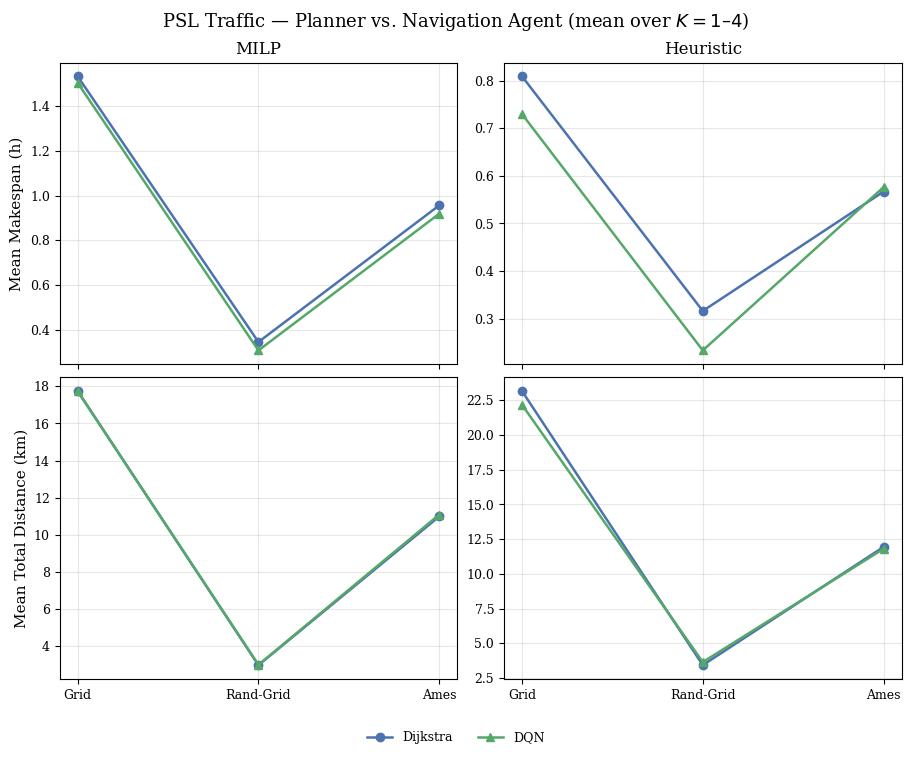

In [4]:
METRICS = [
    ('makespan_h',       'Mean Makespan (h)'),
    ('total_distance_km', 'Mean Total Distance (km)'),
]

# average over K=1-4 (and over network/agent/planner replicates, if any)
agg = (df.groupby(['evrp_planner', 'network', 'trsp_agent'])[[m for m, _ in METRICS]]
         .mean()
         .reset_index())

fig, axes = plt.subplots(2, 2, figsize=(9, 7), constrained_layout=True, sharex='col')
fig.suptitle('PSL Traffic — Planner vs. Navigation Agent (mean over $K=1$–$4$)', fontsize=13)

x = np.arange(len(NET_ORDER))

for col, planner in enumerate(PLANNER_ORDER):
    for row, (metric, ylabel) in enumerate(METRICS):
        ax = axes[row, col]
        sub = agg[agg['evrp_planner'] == planner]
        for agent in AGENT_ORDER:
            s = sub[sub['trsp_agent'] == agent].set_index('network').reindex(NET_ORDER)
            ax.plot(x, s[metric], linestyle='-', marker=AGENT_MARKERS[agent],
                    color=AGENT_COLORS[agent], label=AGENT_LABELS[agent],
                    linewidth=1.8, markersize=6)
        ax.set_xticks(x)
        ax.set_xticklabels(NET_ORDER)
        ax.grid(True, alpha=0.3)
        if row == 0:
            ax.set_title(PLANNER_LABELS[planner])
        if col == 0:
            ax.set_ylabel(ylabel)

handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', bbox_to_anchor=(0.5, -0.02), ncol=2, frameon=False)

out = FIG_DIR / 'ta_evrp_psl_planner_agent_comparison.png'
fig.savefig(out, bbox_inches='tight', dpi=150)
print('Saved:', out)
plt.show()

## Figure: PSL Planner x All Agents Comparison (Bar, Makespan & Distance)

Same layout as above (rows = makespan/distance, columns = MILP/Heuristic), but as grouped bar
charts using `results/ta_evrp_results_psl_thesis.csv`, which covers all TRSP agents (DSP excluded
since it is a non-learning live-replanning baseline, not a navigation policy comparable to the rest).

In [5]:
ALL_AGENT_ORDER  = ['dijkstra', 'sarsa', 'dqn', 'ppo', 'a2c']
ALL_AGENT_LABELS = {'dijkstra': 'Dijkstra', 'sarsa': 'SARSA', 'dqn': 'DQN',
                    'ppo': 'PPO', 'a2c': 'A2C'}
ALL_AGENT_COLORS = {'dijkstra': '#4c72b0', 'sarsa': '#dd8452', 'dqn': '#55a868',
                    'ppo': '#c44e52', 'a2c': '#8172b3'}

df_all = pd.read_csv(BASE / 'results' / 'ta_evrp_results_psl_thesis.csv')
df_all = df_all[df_all['status'] == 'ok'].copy()
df_all = df_all[df_all['trsp_agent'] != 'dsp'].copy()

df_all['network'] = df_all['network_net_path'].map(NET_CODE)

assert df_all['network'].notna().all(), 'unmapped network path(s) found'
assert set(df_all['evrp_planner'].unique()) <= set(PLANNER_ORDER)
assert set(df_all['trsp_agent'].unique()) == set(ALL_AGENT_ORDER)

print(f'Rows: {len(df_all)}')
print(df_all.groupby(['evrp_planner', 'network', 'trsp_agent'])['traffic_psl_K'].count().unstack())

Rows: 120
trsp_agent              a2c  dijkstra  dqn  ppo  sarsa
evrp_planner network                                  
heuristic    Ames         4         4    4    4      4
             Grid         4         4    4    4      4
             Rand-Grid    4         4    4    4      4
milp         Ames         4         4    4    4      4
             Grid         4         4    4    4      4
             Rand-Grid    4         4    4    4      4


Saved: /home/shinobi-owl/PhD/battery/DroneSim/results/figures/ta_evrp_psl_planner_allagents_comparison.png


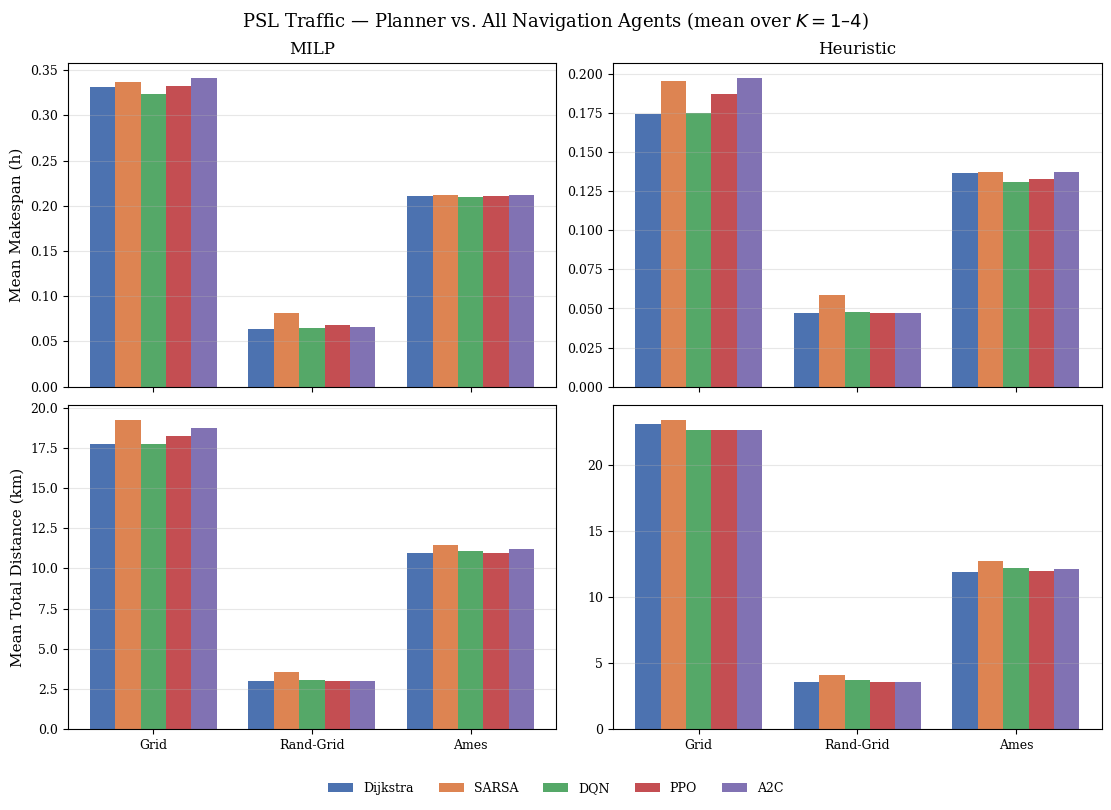

In [6]:
agg_all = (df_all.groupby(['evrp_planner', 'network', 'trsp_agent'])[[m for m, _ in METRICS]]
                  .mean()
                  .reset_index())

fig, axes = plt.subplots(2, 2, figsize=(11, 7.5), constrained_layout=True, sharex='col')
fig.suptitle('PSL Traffic — Planner vs. All Navigation Agents (mean over $K=1$–$4$)', fontsize=13)

n_agents = len(ALL_AGENT_ORDER)
width = 0.8 / n_agents
x = np.arange(len(NET_ORDER))

for col, planner in enumerate(PLANNER_ORDER):
    for row, (metric, ylabel) in enumerate(METRICS):
        ax = axes[row, col]
        sub = agg_all[agg_all['evrp_planner'] == planner]
        for i, agent in enumerate(ALL_AGENT_ORDER):
            s = sub[sub['trsp_agent'] == agent].set_index('network').reindex(NET_ORDER)
            offset = (i - (n_agents - 1) / 2) * width
            ax.bar(x + offset, s[metric], width=width,
                   color=ALL_AGENT_COLORS[agent], label=ALL_AGENT_LABELS[agent])
        ax.set_xticks(x)
        ax.set_xticklabels(NET_ORDER)
        ax.grid(True, axis='y', alpha=0.3)
        if row == 0:
            ax.set_title(PLANNER_LABELS[planner])
        if col == 0:
            ax.set_ylabel(ylabel)

handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', bbox_to_anchor=(0.5, -0.02), ncol=n_agents, frameon=False)

out = FIG_DIR / 'ta_evrp_psl_planner_allagents_comparison.png'
fig.savefig(out, bbox_inches='tight', dpi=150)
print('Saved:', out)
plt.show()

## Figures: Per-Metric K Breakdown (Bar, All Agents)

One figure per metric (makespan, total distance). Each figure: 2 rows (MILP, Heuristic) x 5
columns ($K=1,2,3,4$, then the all-$K$ average). Every panel is a grouped bar chart over the three
networks, with one bar group per TRSP agent (DSP excluded). Uses `results/ta_evrp_results_psl_thesis.csv`.

In [7]:
K_ORDER = [1, 2, 3, 4]
COL_ORDER  = K_ORDER + ['avg']
COL_LABELS = {1: '$K=1$', 2: '$K=2$', 3: '$K=3$', 4: '$K=4$', 'avg': 'Avg over $K$'}


def make_k_breakdown_figure(metric, ylabel, title, filename):
    n_agents = len(ALL_AGENT_ORDER)
    width = 0.8 / n_agents
    x = np.arange(len(NET_ORDER))

    fig, axes = plt.subplots(2, 5, figsize=(20, 7), constrained_layout=True, sharey='row')
    fig.suptitle(title, fontsize=13)

    for row, planner in enumerate(PLANNER_ORDER):
        for col, k in enumerate(COL_ORDER):
            ax = axes[row, col]
            if k == 'avg':
                sub = (df_all[df_all['evrp_planner'] == planner]
                       .groupby(['network', 'trsp_agent'])[metric].mean().reset_index())
            else:
                sub = df_all[(df_all['evrp_planner'] == planner) & (df_all['traffic_psl_K'] == k)]

            for i, agent in enumerate(ALL_AGENT_ORDER):
                s = sub[sub['trsp_agent'] == agent].set_index('network').reindex(NET_ORDER)
                offset = (i - (n_agents - 1) / 2) * width
                ax.bar(x + offset, s[metric], width=width,
                       color=ALL_AGENT_COLORS[agent], label=ALL_AGENT_LABELS[agent])

            ax.set_xticks(x)
            ax.set_xticklabels(NET_ORDER)
            ax.grid(True, axis='y', alpha=0.3)
            if row == 0:
                ax.set_title(COL_LABELS[k])
            if col == 0:
                ax.set_ylabel(f'{PLANNER_LABELS[planner]}\n{ylabel}')

    handles, labels = axes[0, 0].get_legend_handles_labels()
    fig.legend(handles, labels, loc='upper center', bbox_to_anchor=(0.5, -0.02),
               ncol=n_agents, frameon=False)

    out = FIG_DIR / filename
    fig.savefig(out, bbox_inches='tight', dpi=150)
    print('Saved:', out)
    plt.show()

Saved: /home/shinobi-owl/PhD/battery/DroneSim/results/figures/ta_evrp_psl_makespan_k_breakdown.png


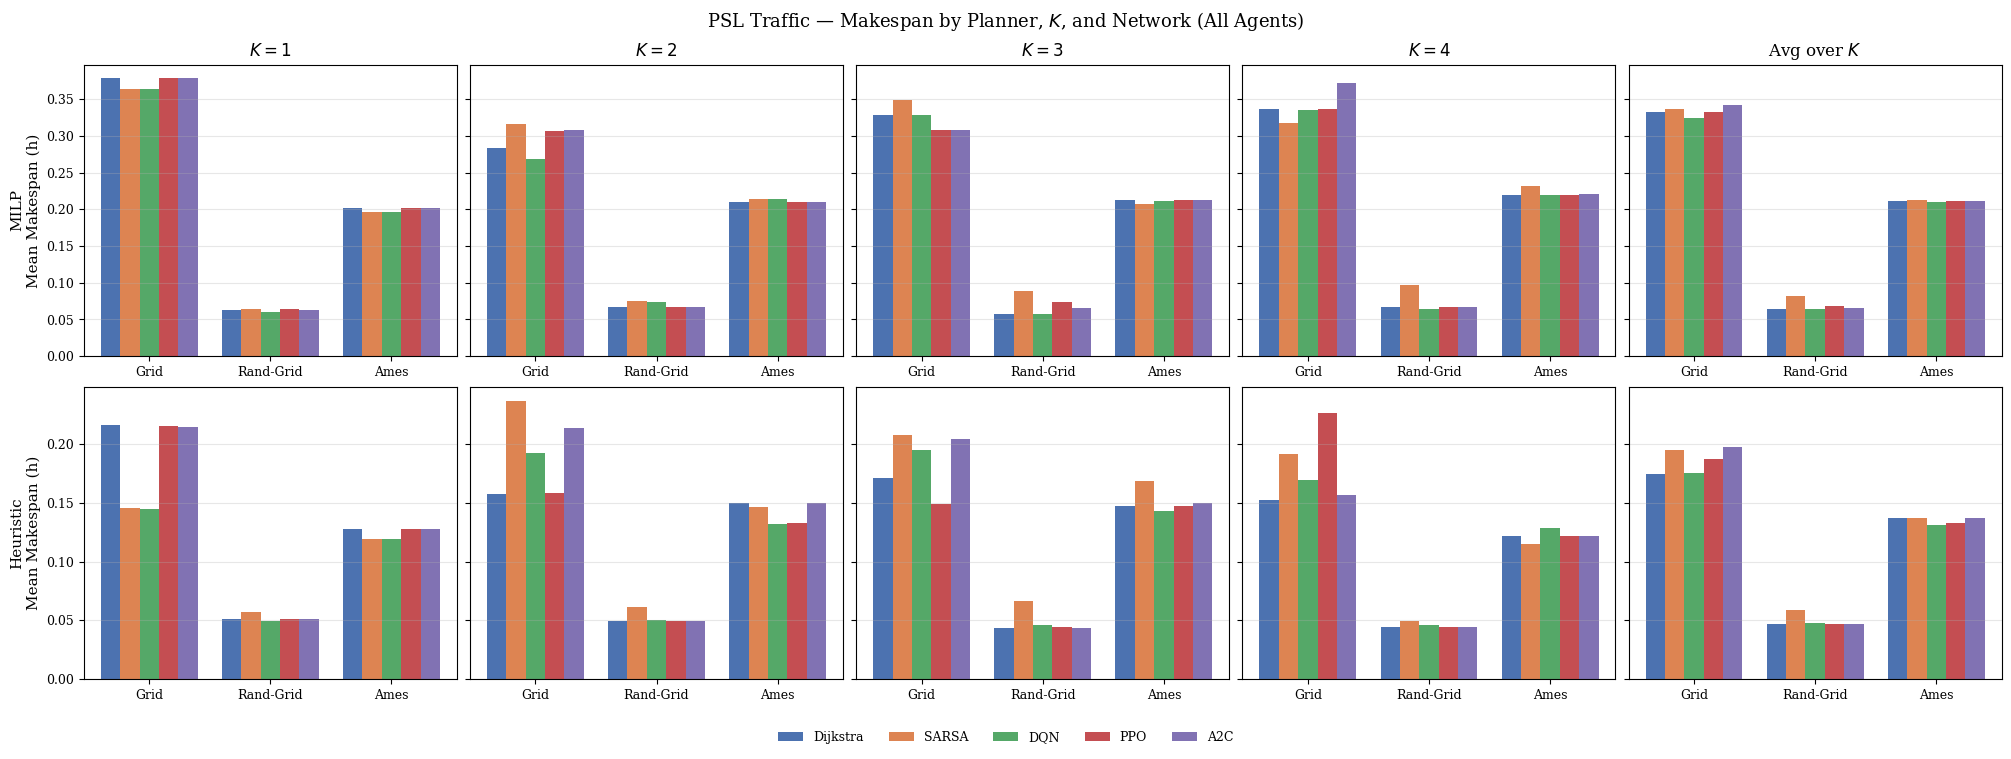

In [8]:
make_k_breakdown_figure(
    metric='makespan_h',
    ylabel='Mean Makespan (h)',
    title='PSL Traffic — Makespan by Planner, $K$, and Network (All Agents)',
    filename='ta_evrp_psl_makespan_k_breakdown.png',
)

Saved: /home/shinobi-owl/PhD/battery/DroneSim/results/figures/ta_evrp_psl_distance_k_breakdown.png


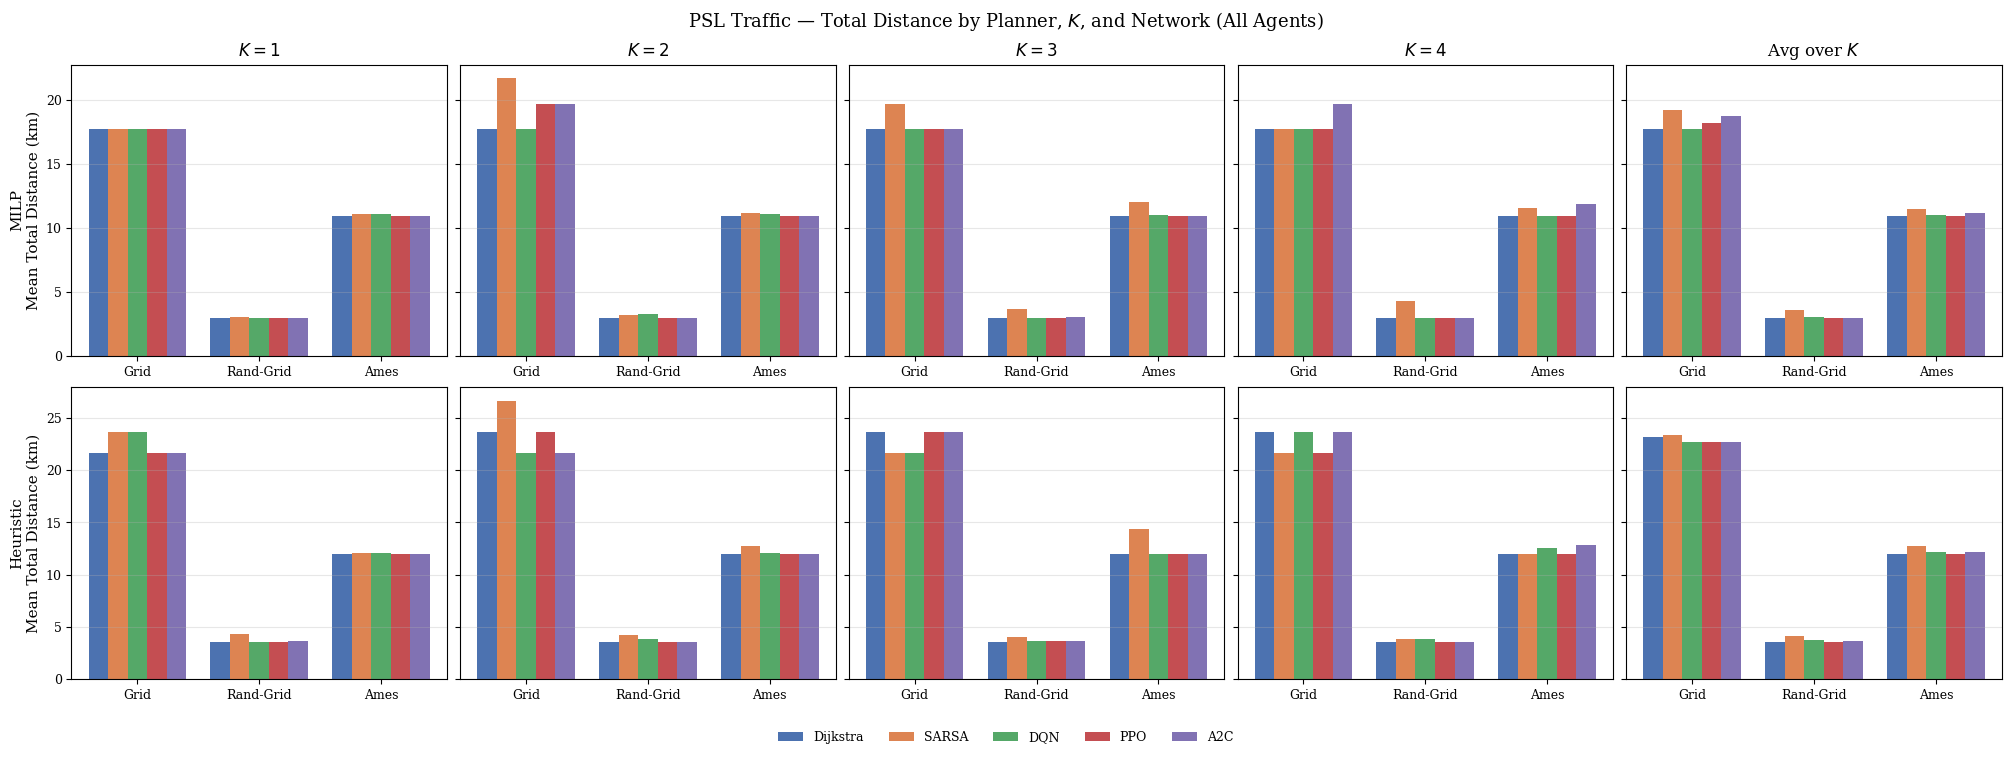

In [9]:
make_k_breakdown_figure(
    metric='total_distance_km',
    ylabel='Mean Total Distance (km)',
    title='PSL Traffic — Total Distance by Planner, $K$, and Network (All Agents)',
    filename='ta_evrp_psl_distance_k_breakdown.png',
)

## Figure: SVC Planner x Agent Comparison (Bar, Makespan & Distance)

2 rows (MILP, Heuristic) x 2 columns (makespan, total distance). Each panel is a grouped bar
chart over the three networks, with one bar group per TRSP agent (all six agents, including DSP,
since under SVC background traffic DSP is a live-replanning navigation baseline rather than a
static-path agent). Uses `results/ta_evrp_results_svc_thesis.csv`.

In [10]:
SVC_AGENT_ORDER  = ['dijkstra', 'dsp', 'sarsa_svc', 'dqn_svc', 'a2c_svc', 'ppo_svc']
SVC_AGENT_LABELS = {'dijkstra': 'Dijkstra', 'dsp': 'DSP', 'sarsa_svc': 'SARSA',
                    'dqn_svc': 'DQN', 'a2c_svc': 'A2C', 'ppo_svc': 'PPO'}
SVC_AGENT_COLORS = {'dijkstra': '#4c72b0', 'dsp': '#937860', 'sarsa_svc': '#dd8452',
                    'dqn_svc': '#55a868', 'a2c_svc': '#8172b3', 'ppo_svc': '#c44e52'}

df_svc = pd.read_csv(BASE / 'results' / 'ta_evrp_results_svc_thesis.csv')
df_svc = df_svc[df_svc['status'] == 'ok'].copy()

df_svc['network'] = df_svc['network_net_path'].map(NET_CODE)

assert df_svc['network'].notna().all(), 'unmapped network path(s) found'
assert set(df_svc['evrp_planner'].unique()) <= set(PLANNER_ORDER)
assert set(df_svc['trsp_agent'].unique()) == set(SVC_AGENT_ORDER)

print(f'Rows: {len(df_svc)}')
print(df_svc.groupby(['evrp_planner', 'network', 'trsp_agent']).size().unstack())

Rows: 36
trsp_agent              a2c_svc  dijkstra  dqn_svc  dsp  ppo_svc  sarsa_svc
evrp_planner network                                                       
heuristic    Ames             1         1        1    1        1          1
             Grid             1         1        1    1        1          1
             Rand-Grid        1         1        1    1        1          1
milp         Ames             1         1        1    1        1          1
             Grid             1         1        1    1        1          1
             Rand-Grid        1         1        1    1        1          1


Saved: /home/shinobi-owl/PhD/battery/DroneSim/results/figures/ta_evrp_svc_planner_agent_comparison.png


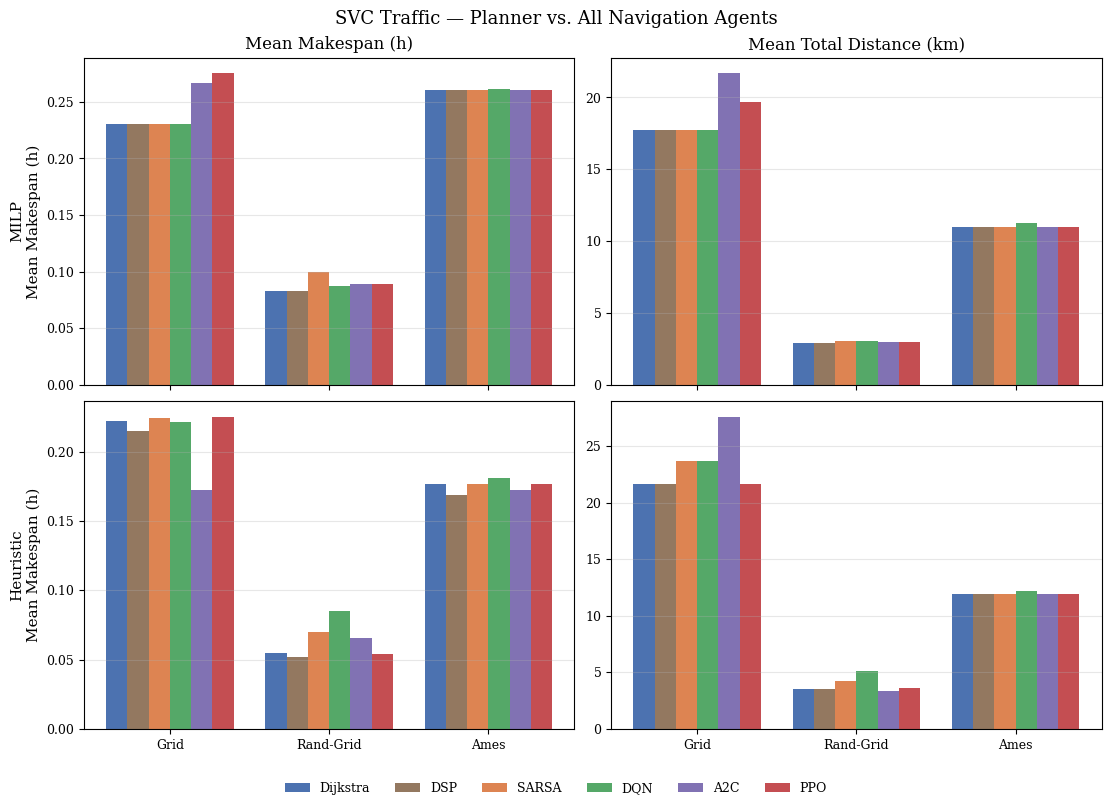

In [11]:
n_agents = len(SVC_AGENT_ORDER)
width = 0.8 / n_agents
x = np.arange(len(NET_ORDER))

fig, axes = plt.subplots(2, 2, figsize=(11, 7.5), constrained_layout=True, sharex='col')
fig.suptitle('SVC Traffic — Planner vs. All Navigation Agents', fontsize=13)

for row, planner in enumerate(PLANNER_ORDER):
    for col, (metric, ylabel) in enumerate(METRICS):
        ax = axes[row, col]
        sub = df_svc[df_svc['evrp_planner'] == planner]
        for i, agent in enumerate(SVC_AGENT_ORDER):
            s = sub[sub['trsp_agent'] == agent].set_index('network').reindex(NET_ORDER)
            offset = (i - (n_agents - 1) / 2) * width
            ax.bar(x + offset, s[metric], width=width,
                   color=SVC_AGENT_COLORS[agent], label=SVC_AGENT_LABELS[agent])
        ax.set_xticks(x)
        ax.set_xticklabels(NET_ORDER)
        ax.grid(True, axis='y', alpha=0.3)
        if col == 0:
            ax.set_ylabel(f'{PLANNER_LABELS[planner]}\n{ylabel}')
        if row == 0:
            ax.set_title(ylabel)

handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper center', bbox_to_anchor=(0.5, -0.02), ncol=n_agents, frameon=False)

out = FIG_DIR / 'ta_evrp_svc_planner_agent_comparison.png'
fig.savefig(out, bbox_inches='tight', dpi=150)
print('Saved:', out)
plt.show()